# **Muhammad Ibtisam Afzal**

# Assignment No. 7: Classification Algorithms and Imbalanced Datasets

**Dataset:** Synthetic customer churn data (1,000 records). Target: `Churn` (0 = No Churn, 1 = Churn).

This notebook answers all six questions: identify class imbalance, apply SMOTE, train SVM, Decision Tree, and Random Forest (bagging), then compare their performance.

**Methodology:** Split the data before applying SMOTE. SMOTE is used only on the training set; the test set keeps its original class distribution to prevent data leakage.

## 1. Install and import libraries

In [1]:
%pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, classification_report,
    confusion_matrix
)
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create a customer churn dataset

In [2]:
# Reproducible synthetic customer data with a minority churn class.
n = 1000
rng = np.random.default_rng(RANDOM_STATE)

tenure = rng.integers(1, 73, n)
monthly = rng.normal(70, 20, n).clip(20, 130)
support = rng.poisson(2.0, n).clip(0, 10)
contract = rng.choice([0, 1, 2], n, p=[0.55, 0.30, 0.15])
internet = rng.choice([0, 1], n, p=[0.25, 0.75])
total = (tenure * monthly + rng.normal(0, 100, n)).clip(0)

logit = (-2.15 - 0.035*(tenure-24) + 0.025*(monthly-70)
         + 0.38*support + 0.75*(contract == 0)
         - 0.65*(contract == 2) + 0.25*internet)
prob = 1 / (1 + np.exp(-logit))
churn = rng.binomial(1, prob)

df = pd.DataFrame({
    "Tenure": tenure,
    "MonthlyCharges": monthly.round(2),
    "SupportCalls": support,
    "ContractType": contract,
    "InternetService": internet,
    "TotalCharges": total.round(2),
    "Churn": churn
})

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().round(2))

Dataset shape: (1000, 7)


,Tenure,MonthlyCharges,SupportCalls,ContractType,InternetService,TotalCharges,Churn
0,7,98.66,4,0,1,718.63,1
1,56,71.83,2,0,1,4278.95,0
2,48,81.62,1,0,1,3905.39,0
3,32,68.86,0,2,1,2160.12,0
4,32,66.59,2,2,0,2232.47,0


,Tenure,MonthlyCharges,SupportCalls,ContractType,InternetService,TotalCharges,Churn
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,36.73,69.62,1.97,0.55,0.74,2574.10,0.26
std,20.79,20.24,1.42,0.72,0.44,1704.75,0.44
min,1.00,20.00,0.00,0.00,0.00,0.00,0.00
25%,18.00,56.27,1.00,0.00,0.00,1124.53,0.00
50%,37.00,70.07,2.00,0.00,1.00,2357.79,0.00
75%,55.00,82.72,3.00,1.00,1.00,3787.73,1.00
max,72.00,130.00,7.00,2.00,1.00,7687.69,1.00


### Dataset features

- **Tenure:** Number of months as a customer.
- **MonthlyCharges:** Monthly bill amount.
- **SupportCalls:** Number of support calls.
- **ContractType:** Encoded contract category (0, 1, or 2).
- **InternetService:** Encoded service indicator (0 or 1).
- **TotalCharges:** Approximate accumulated charges.
- **Churn:** Target class; 0 = No Churn, 1 = Churn.

This is synthetic teaching data, not actual customer information.

## Question 1: Identify whether the dataset is balanced or imbalanced

,Class,Count,Percentage
0,No Churn (0),740,74.0
1,Churn (1),260,26.0


Majority-to-minority ratio: 2.85:1
Conclusion: Imbalanced dataset


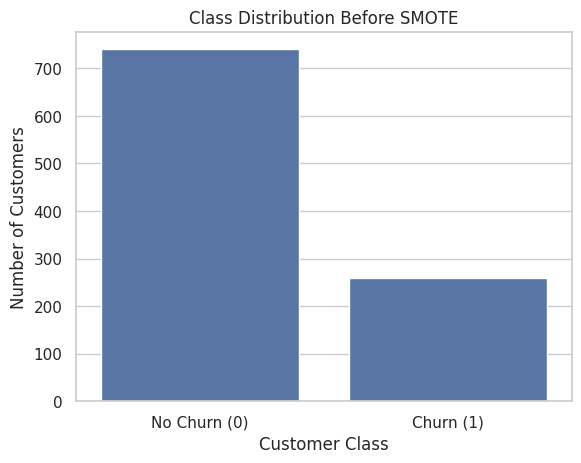

In [3]:
counts = df["Churn"].value_counts().sort_index()
summary = pd.DataFrame({
    "Class": ["No Churn (0)", "Churn (1)"],
    "Count": [counts.get(0, 0), counts.get(1, 0)],
    "Percentage": [counts.get(0, 0)/len(df)*100, counts.get(1, 0)/len(df)*100]
})
display(summary.round(2))

ratio = counts.max() / counts.min()
print(f"Majority-to-minority ratio: {ratio:.2f}:1")
print("Conclusion:", "Imbalanced dataset" if ratio >= 1.5 else "Relatively balanced dataset")

sns.countplot(data=df, x="Churn")
plt.xticks([0, 1], ["No Churn (0)", "Churn (1)"])
plt.title("Class Distribution Before SMOTE")
plt.xlabel("Customer Class")
plt.ylabel("Number of Customers")
plt.show()

**Explanation:** A dataset is imbalanced when one target class has substantially more examples than another. Accuracy alone can be misleading in this situation. Precision, recall, F1-score, balanced accuracy, ROC-AUC, and a confusion matrix are also used below.

## Prepare training and testing data

In [4]:
features = ["Tenure", "MonthlyCharges", "SupportCalls",
            "ContractType", "InternetService", "TotalCharges"]
X = df[features]
y = df["Churn"]

# Split first, then resample training data only.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training classes before SMOTE:")
display(y_train.value_counts().sort_index())
print("Testing classes (not resampled):")
display(y_test.value_counts().sort_index())

Training records: 800
Testing records: 200
Training classes before SMOTE:


,count
Churn,
0,592
1,208


Testing classes (not resampled):


,count
Churn,
0,148
1,52


## Question 2: Apply SMOTE to handle class imbalance

SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic minority-class examples by interpolating between existing minority-class observations. It is applied only to the training data.

Training class counts after SMOTE:


,count
Churn,
0,592
1,592


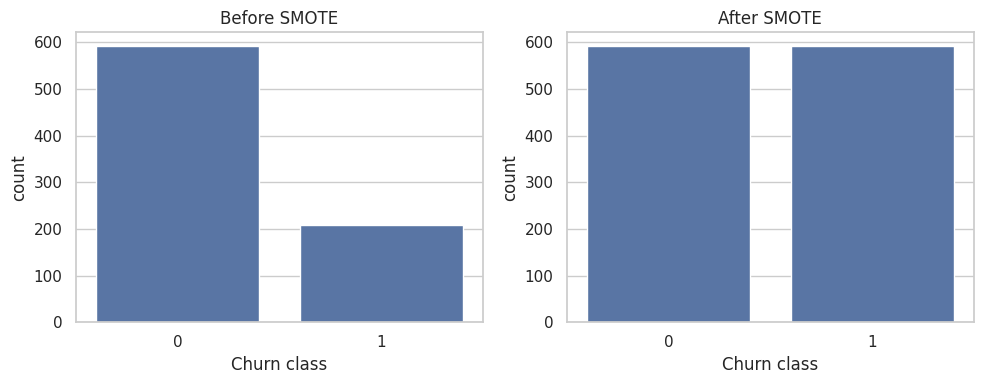

In [5]:
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Training class counts after SMOTE:")
display(y_train_smote.value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Churn class")
sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Churn class")
plt.tight_layout()
plt.show()

**Result:** SMOTE balances the training classes. The test set remains unchanged, which avoids data leakage and gives a fairer estimate of performance on the original class distribution.

## Questions 3–5: Train the three classification algorithms

- **SVM:** Learns a decision boundary between classes. Standardization is used because SVM is sensitive to feature scale.
- **Decision Tree:** Learns decision rules by recursively splitting the feature space.
- **Random Forest:** Combines many decision trees. It uses bootstrap samples and random feature selection; aggregating the trees is the bagging principle.

In [6]:
# SVM classifier
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale",
                       probability=True, random_state=RANDOM_STATE))
])
svm_model.fit(X_train_smote, y_train_smote)

# Decision Tree classifier
tree_model = DecisionTreeClassifier(
    max_depth=6, min_samples_split=10, min_samples_leaf=5,
    random_state=RANDOM_STATE
)
tree_model.fit(X_train_smote, y_train_smote)

# Random Forest: bootstrap aggregation (bagging) of decision trees
forest_model = RandomForestClassifier(
    n_estimators=200, max_features="sqrt", bootstrap=True,
    random_state=RANDOM_STATE, n_jobs=-1
)
forest_model.fit(X_train_smote, y_train_smote)

models = {
    "SVM": svm_model,
    "Decision Tree": tree_model,
    "Random Forest (Bagging)": forest_model
}
print("All three models trained successfully.")

All three models trained successfully.


## Question 6: Compare model performance

In [7]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    probabilities[name] = proba

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Churn)": precision_score(y_test, pred, zero_division=0),
        "Recall (Churn)": recall_score(y_test, pred, zero_division=0),
        "F1-score (Churn)": f1_score(y_test, pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))
print("Models are evaluated on the same untouched test set.")

,Accuracy,Precision (Churn),Recall (Churn),F1-score (Churn),Balanced Accuracy,ROC-AUC
Model,,,,,,
SVM,0.65,0.395,0.654,0.493,0.651,0.692
Decision Tree,0.71,0.456,0.596,0.517,0.673,0.734
Random Forest (Bagging),0.66,0.400,0.615,0.485,0.646,0.724


Models are evaluated on the same untouched test set.


### Confusion matrices and classification reports

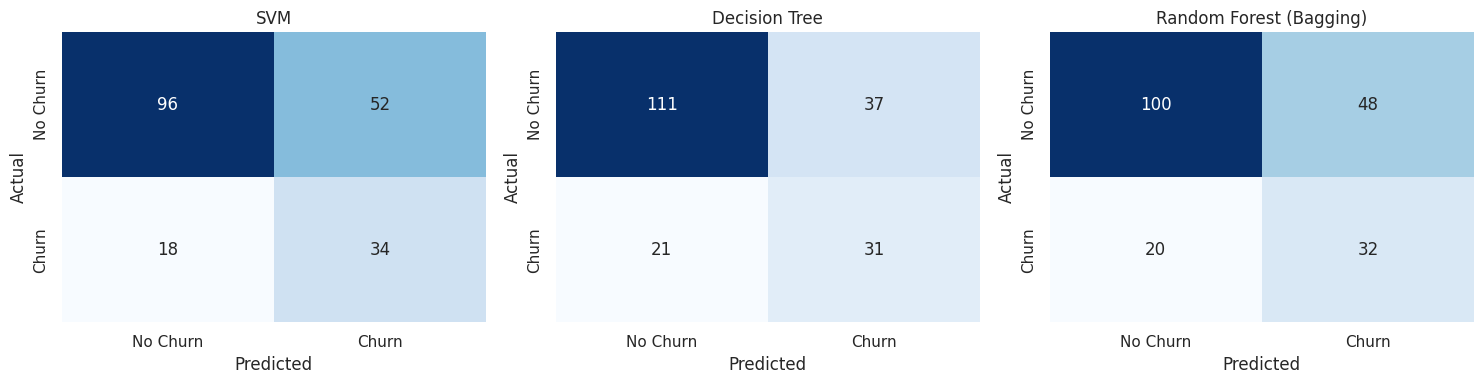

\n=======================================================
SVM
              precision    recall  f1-score   support

    No Churn       0.84      0.65      0.73       148
       Churn       0.40      0.65      0.49        52

    accuracy                           0.65       200
   macro avg       0.62      0.65      0.61       200
weighted avg       0.73      0.65      0.67       200

\n=======================================================
Decision Tree
              precision    recall  f1-score   support

    No Churn       0.84      0.75      0.79       148
       Churn       0.46      0.60      0.52        52

    accuracy                           0.71       200
   macro avg       0.65      0.67      0.65       200
weighted avg       0.74      0.71      0.72       200

\n=======================================================
Random Forest (Bagging)
              precision    recall  f1-score   support

    No Churn       0.83      0.68      0.75       148
       Churn       0.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Churn", "Churn"],
                yticklabels=["No Churn", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

for name, pred in predictions.items():
    print("\\n" + "="*55)
    print(name)
    print(classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["No Churn", "Churn"], zero_division=0
    ))

### Actual versus predicted churn labels

In [9]:
comparison = pd.DataFrame({
    "Actual Churn": y_test,
    "SVM Prediction": predictions["SVM"],
    "Decision Tree Prediction": predictions["Decision Tree"],
    "Random Forest Prediction": predictions["Random Forest (Bagging)"]
}, index=y_test.index).sort_index()
display(comparison.head(20))

correct = pd.DataFrame({
    "Model": list(predictions.keys()),
    "Correct Predictions": [
        int((predictions[name] == y_test.to_numpy()).sum())
        for name in predictions
    ],
    "Test Records": [len(y_test)] * len(predictions)
})
correct["Correct Percentage"] = 100 * correct["Correct Predictions"] / correct["Test Records"]
display(correct.round(2))

,Actual Churn,SVM Prediction,Decision Tree Prediction,Random Forest Prediction
2,0,1,0,0
5,0,0,0,0
18,0,0,0,0
19,0,1,1,0
25,0,1,0,0
27,0,0,0,0
36,0,0,0,1
43,0,1,1,1
45,0,0,0,0
47,0,0,0,0


,Model,Correct Predictions,Test Records,Correct Percentage
0,SVM,130,200,65.0
1,Decision Tree,142,200,71.0
2,Random Forest (Bagging),132,200,66.0


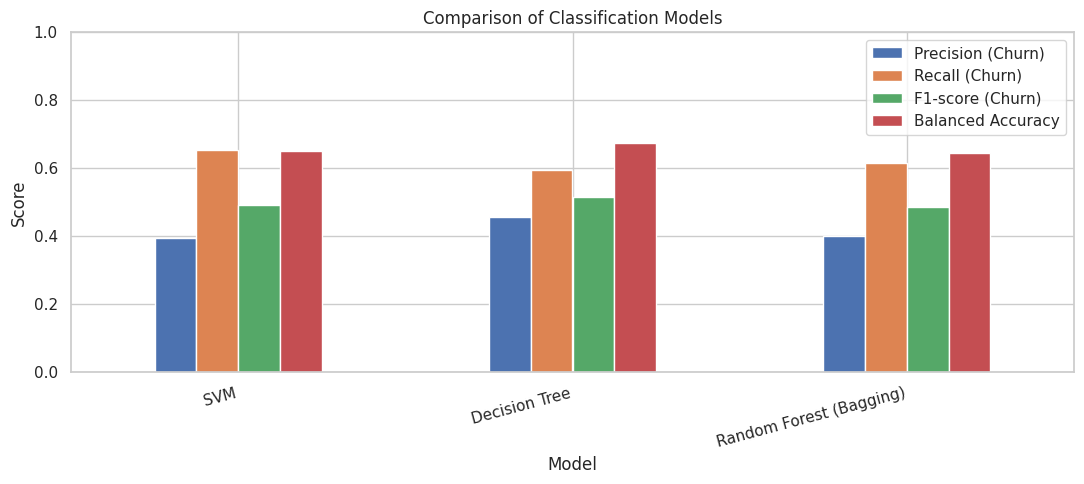

Best model by Churn-class F1-score: Decision Tree


In [10]:
# Compare minority-class precision, recall, F1 and balanced accuracy.
metric_cols = ["Precision (Churn)", "Recall (Churn)",
               "F1-score (Churn)", "Balanced Accuracy"]
results_df[metric_cols].plot(kind="bar", figsize=(11, 5))
plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

best_name = results_df["F1-score (Churn)"].idxmax()
print("Best model by Churn-class F1-score:", best_name)

## Final Conclusion

1. Class counts and percentages were used to identify imbalance in the customer-churn target.
2. SMOTE was applied to the training data only to balance the minority class.
3. An SVM classifier was trained using standardized features.
4. A Decision Tree classifier was trained on the SMOTE-resampled data.
5. A Random Forest classifier was trained using bootstrap aggregation (bagging) of decision trees.
6. All three models were compared on the same original test set using accuracy, precision, recall, F1-score, balanced accuracy, ROC-AUC, confusion matrices, and actual-versus-predicted records.

**Interpretation note:** For churn detection, recall and F1-score for the Churn class are important because missing customers who will churn can be costly. The best model should be selected based on the business objective, not accuracy alone.

**Dataset limitation:** This synthetic dataset demonstrates the required algorithms and workflow. The scores are specific to generated data and are not evidence of real-world customer-churn performance.